# Csődöt megelőző pénzügyi mutatók – elemzés
Adat: Polish companies bankruptcy data (UCI #365), tisztítva: `data_clean/polish_clean.csv` (`scripts/prep.py`).

`ev_a_csodig` = hány évvel a státusz megállapítása előtt mértük a mutatókat (1 = utolsó év a csőd előtt, 5 = 5 évvel előtte).

Részek:
1. Leíró elemzés – figyelmeztető jelek (A)
2. Melyik mutatócsoport jelez legjobban, és mikortól? (A)
3. Előrejelző modellek (B)
4. Altman Z-score viszonyítás + bukási profilok klaszterezéssel (C)

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score
from sklearn.cluster import KMeans
from xgboost import XGBClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "abrak"; FIG.mkdir(exist_ok=True)
df = pd.read_csv(ROOT / "data_clean/polish_clean.csv")
szotar = pd.read_csv(ROOT / "data_clean/mutato_szotar.csv")
X_COLS = [f"X{i}" for i in range(1, 65)]
CSOPORT = dict(zip(szotar.mutato, szotar.csoport))
sns.set_theme(style="whitegrid", context="notebook")
SZINEK = {"Működő": "#4C78A8", "Csődbe ment": "#E45756"}
df["statusz"] = df.csod.map({0: "Működő", 1: "Csődbe ment"})
df.groupby("ev_a_csodig").csod.agg(megfigyeles="count", csod="sum", arany="mean").round(3)

,megfigyeles,csod,arany
ev_a_csodig,,,
1,5850,408,0.070
2,9710,513,0.053
3,10416,493,0.047
4,10083,398,0.039
5,6945,271,0.039


## 1. Kulcsmutatók mediánja a csőd előtti években

,ev_a_csodig,statusz,X1,X7,X6,X2,X10,X4,X46,X40,X3
0,1,Csődbe ment,-0.067,-0.071,-0.012,0.725,0.255,0.962,0.470,0.047,-0.013
1,1,Működő,0.052,0.062,0.000,0.436,0.538,1.711,1.117,0.191,0.233
2,2,Csődbe ment,0.000,0.000,0.000,0.673,0.305,1.060,0.528,0.066,0.030
3,2,Működő,0.044,0.052,0.000,0.458,0.519,1.630,1.074,0.193,0.209
4,3,Csődbe ment,0.004,0.006,0.000,0.665,0.318,1.138,0.597,0.070,0.062
5,3,Működő,0.045,0.054,0.000,0.457,0.525,1.645,1.087,0.204,0.206
6,4,Csődbe ment,0.013,0.017,0.000,0.639,0.335,1.135,0.583,0.083,0.058
7,4,Működő,0.052,0.063,0.000,0.481,0.499,1.551,1.021,0.178,0.196
8,5,Csődbe ment,0.021,0.026,0.000,0.648,0.333,1.097,0.588,0.058,0.047
9,5,Működő,0.078,0.092,0.000,0.476,0.498,1.522,0.983,0.161,0.187


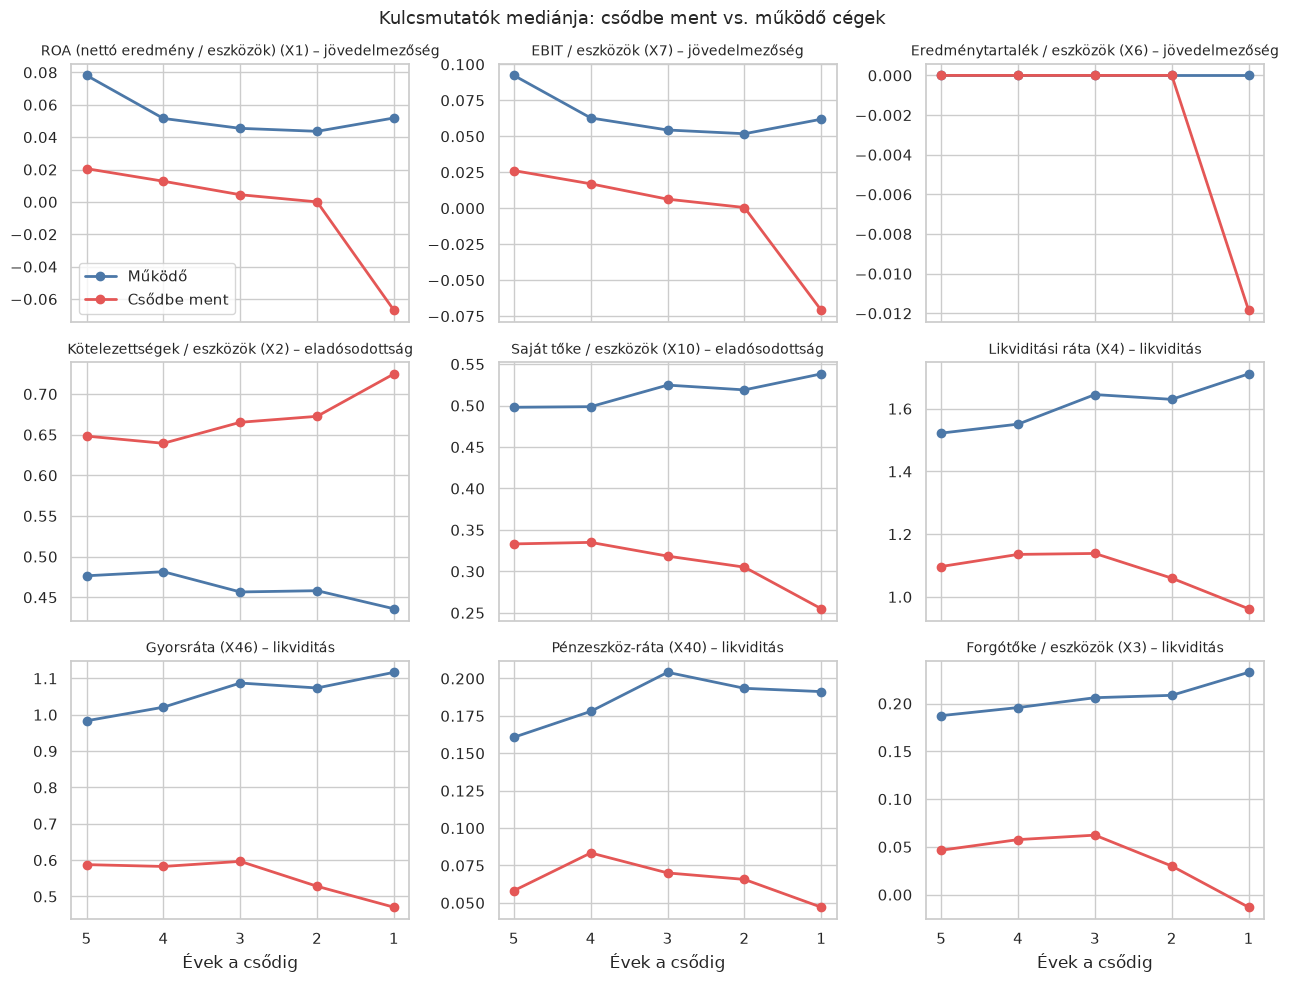

In [2]:
KULCS = {
    "X1": "ROA (nettó eredmény / eszközök)",
    "X7": "EBIT / eszközök",
    "X6": "Eredménytartalék / eszközök",
    "X2": "Kötelezettségek / eszközök",
    "X10": "Saját tőke / eszközök",
    "X4": "Likviditási ráta",
    "X46": "Gyorsráta",
    "X40": "Pénzeszköz-ráta",
    "X3": "Forgótőke / eszközök",
}
med = df.groupby(["ev_a_csodig", "statusz"])[list(KULCS)].median().reset_index()
fig, axes = plt.subplots(3, 3, figsize=(13, 10), sharex=True)
for ax, (col, nev) in zip(axes.flat, KULCS.items()):
    for st, c in SZINEK.items():
        s = med[med.statusz == st]
        ax.plot(s.ev_a_csodig, s[col], marker="o", color=c, label=st, lw=2)
    ax.set_title(f"{nev} ({col}) – {CSOPORT[col]}", fontsize=10)
    ax.invert_xaxis(); ax.set_xticks([5, 4, 3, 2, 1])
for ax in axes[-1]: ax.set_xlabel("Évek a csődig")
axes[0, 0].legend()
fig.suptitle("Kulcsmutatók mediánja: csődbe ment vs. működő cégek", fontsize=13)
fig.tight_layout(); fig.savefig(FIG / "01_kulcsmutatok_median.png", dpi=200)
med.round(3)

## 2. Melyik mutatócsoport különít el legjobban, és hány évvel előre?
Minden mutatóra és horizontra: Mann–Whitney U-próba + egyváltozós AUC (|AUC − 0,5| = elkülönítő erő, iránytól függetlenül).

ev_a_csodig,1,2,3,4,5
csoport,,,,,
eladósodottság,0.428,0.343,0.323,0.255,0.301
jövedelmezőség,0.531,0.369,0.338,0.228,0.328
likviditás,0.401,0.288,0.270,0.214,0.269


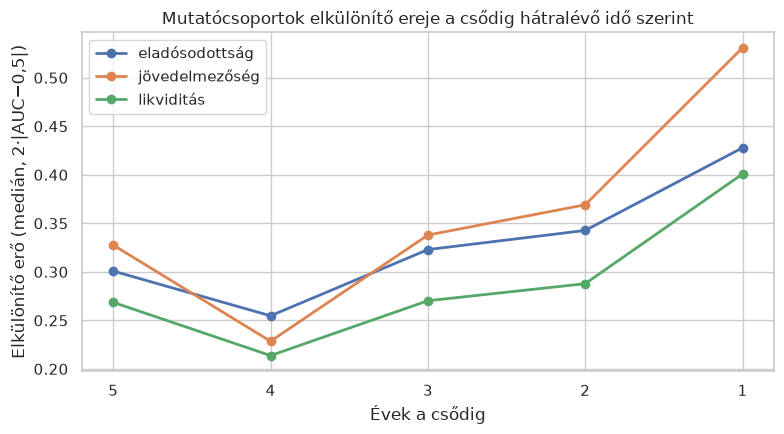

In [3]:
rows = []
for h, g in df.groupby("ev_a_csodig"):
    for col in X_COLS:
        s = g[[col, "csod"]].dropna()
        a, b = s[s.csod == 1][col], s[s.csod == 0][col]
        p = mannwhitneyu(a, b).pvalue
        auc = roc_auc_score(s.csod, s[col])
        rows.append(dict(ev_a_csodig=h, mutato=col, csoport=CSOPORT[col], auc=auc,
                         ero=abs(auc - 0.5) * 2, p=p, med_csod=a.median(), med_mukodo=b.median()))
uni = pd.DataFrame(rows)
fokusz = uni[uni.csoport.isin(["likviditás", "eladósodottság", "jövedelmezőség"])]
cs = fokusz.groupby(["csoport", "ev_a_csodig"]).ero.median().unstack()
fig, ax = plt.subplots(figsize=(8, 4.5))
for csop, row in cs.iterrows():
    ax.plot(row.index, row.values, marker="o", lw=2, label=csop)
ax.invert_xaxis(); ax.set_xticks([5, 4, 3, 2, 1])
ax.set_xlabel("Évek a csődig"); ax.set_ylabel("Elkülönítő erő (medián, 2·|AUC−0,5|)")
ax.set_title("Mutatócsoportok elkülönítő ereje a csődig hátralévő idő szerint"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "02_csoport_ero.png", dpi=200)
cs.round(3)

In [4]:
# Top 10 mutató horizontonként (1 = legközelebb a csődhöz)
top = (uni.sort_values("ero", ascending=False).groupby("ev_a_csodig").head(10)
         .merge(szotar[["mutato", "leiras"]], on="mutato")
         .sort_values(["ev_a_csodig", "ero"], ascending=[True, False]))
top[["ev_a_csodig", "mutato", "csoport", "leiras", "auc", "p", "med_csod", "med_mukodo"]].round(3)

,ev_a_csodig,mutato,csoport,leiras,auc,p,med_csod,med_mukodo
0,1,X26,eladósodottság,(net profit + depreciation) / total liabilities,0.205,0.0,-0.053,0.237
1,1,X16,eladósodottság,(gross profit + depreciation) / total liabilities,0.207,0.0,-0.052,0.260
2,1,X39,jövedelmezőség,profit on sales / sales,0.213,0.0,-0.050,0.043
3,1,X13,jövedelmezőség,(gross profit + depreciation) / sales,0.217,0.0,-0.025,0.072
4,1,X45,jövedelmezőség,net profit / inventory,0.217,0.0,-0.366,0.287
5,1,X35,jövedelmezőség,profit on sales / total assets,0.220,0.0,-0.069,0.066
6,1,X12,eladósodottság,gross profit / short-term liabilities,0.222,0.0,-0.132,0.190
7,1,X23,jövedelmezőség,net profit / sales,0.228,0.0,-0.049,0.033
8,1,X19,jövedelmezőség,gross profit / sales,0.230,0.0,-0.049,0.040
9,1,X31,jövedelmezőség,(gross profit + interest) / sales,0.233,0.0,-0.039,0.047


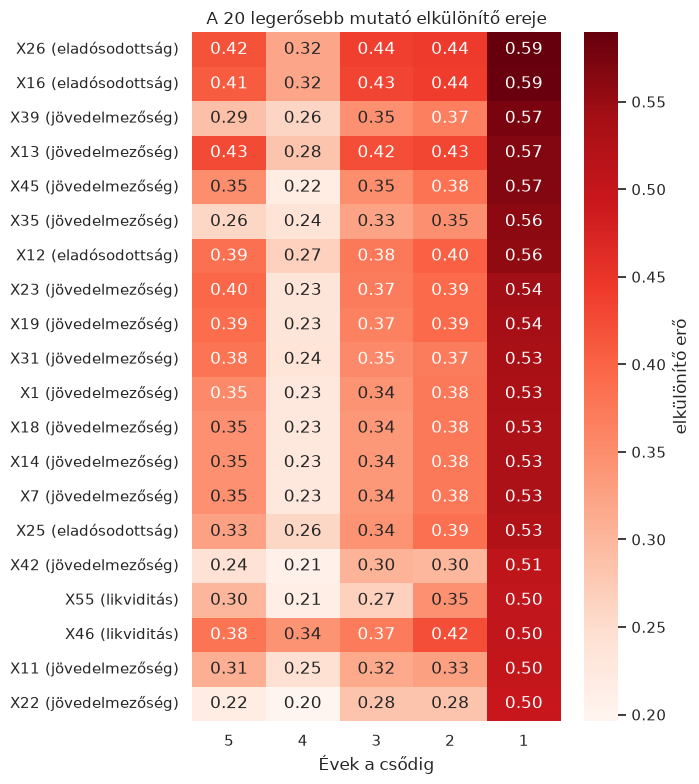

In [5]:
piv = uni.pivot(index="mutato", columns="ev_a_csodig", values="ero")
piv = piv.loc[piv[1].sort_values(ascending=False).index[:20]]
piv.index = [f"{m} ({CSOPORT[m]})" for m in piv.index]
fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(piv[[5, 4, 3, 2, 1]], annot=True, fmt=".2f", cmap="Reds", ax=ax, cbar_kws={"label": "elkülönítő erő"})
ax.set_xlabel("Évek a csődig"); ax.set_ylabel("")
ax.set_title("A 20 legerősebb mutató elkülönítő ereje")
fig.tight_layout(); fig.savefig(FIG / "03_top20_heatmap.png", dpi=200)

## 3. Előrejelző modellek horizontonként
Rétegzett 5-szörös keresztvalidáció. Kiegyensúlyozatlan osztályok → osztálysúlyozás; metrikák: ROC-AUC, recall, precízió, F1 (accuracy félrevezető lenne ~95% működő cégnél).

In [6]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """1. és 99. percentilisre vágja a szélsőértékeket (a tanító halmazon tanulva)."""
    def __init__(self, q=0.01): self.q = q
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_, self.hi_ = np.nanquantile(X, self.q, axis=0), np.nanquantile(X, 1 - self.q, axis=0)
        return self
    def transform(self, X): return np.clip(np.asarray(X, float), self.lo_, self.hi_)

def modellek(pos_weight):
    return {
        "Logisztikus regresszió": make_pipeline(SimpleImputer(strategy="median"), Winsorizer(), StandardScaler(),
                                                LogisticRegression(class_weight="balanced", max_iter=2000)),
        "Döntési fa": make_pipeline(SimpleImputer(strategy="median"),
                                    DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)),
        "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                                       RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                                              n_jobs=-1, random_state=42)),
        "XGBoost": XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                 scale_pos_weight=pos_weight, eval_metric="auc", n_jobs=-1, random_state=42),
    }

cv = StratifiedKFold(5, shuffle=True, random_state=42)
eredm = []
for h, g in df.groupby("ev_a_csodig"):
    X, y = g[X_COLS], g.csod
    for nev, m in modellek((y == 0).sum() / (y == 1).sum()).items():
        r = cross_validate(m, X, y, cv=cv, scoring=["roc_auc", "recall", "precision", "f1"], n_jobs=1)
        eredm.append(dict(ev_a_csodig=h, modell=nev, **{k[5:]: v.mean() for k, v in r.items() if k.startswith("test_")}))
eredm = pd.DataFrame(eredm)
eredm.pivot(index="modell", columns="ev_a_csodig", values="roc_auc").round(3)

ev_a_csodig,1,2,3,4,5
modell,,,,,
Döntési fa,0.819,0.784,0.802,0.794,0.807
Logisztikus regresszió,0.849,0.771,0.752,0.738,0.795
Random Forest,0.913,0.884,0.872,0.871,0.913
XGBoost,0.956,0.938,0.928,0.922,0.961


In [7]:
eredm.round(3)

,ev_a_csodig,modell,roc_auc,recall,precision,f1
0,1,Logisztikus regresszió,0.849,0.718,0.255,0.376
1,1,Döntési fa,0.819,0.721,0.295,0.418
2,1,Random Forest,0.913,0.336,0.616,0.432
3,1,XGBoost,0.956,0.694,0.727,0.709
4,2,Logisztikus regresszió,0.771,0.643,0.135,0.223
5,2,Döntési fa,0.784,0.688,0.161,0.260
6,2,Random Forest,0.884,0.092,0.599,0.158
7,2,XGBoost,0.938,0.635,0.664,0.648
8,3,Logisztikus regresszió,0.752,0.669,0.109,0.187
9,3,Döntési fa,0.802,0.718,0.129,0.218


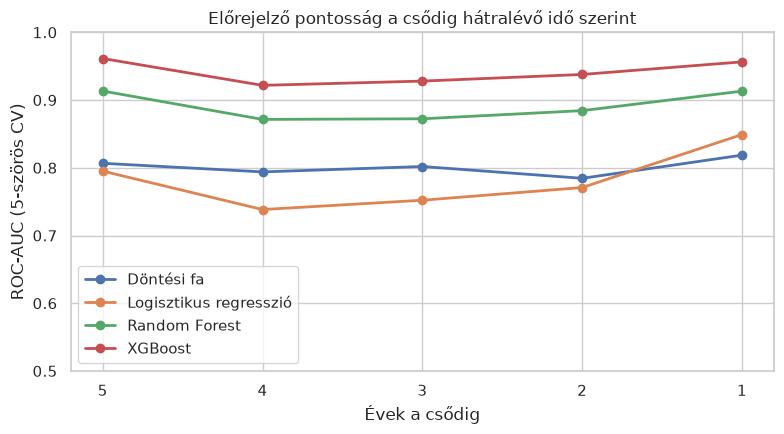

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for nev, s in eredm.groupby("modell"):
    ax.plot(s.ev_a_csodig, s.roc_auc, marker="o", lw=2, label=nev)
ax.invert_xaxis(); ax.set_xticks([5, 4, 3, 2, 1]); ax.set_ylim(0.5, 1)
ax.set_xlabel("Évek a csődig"); ax.set_ylabel("ROC-AUC (5-szörös CV)")
ax.set_title("Előrejelző pontosság a csődig hátralévő idő szerint"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "04_modell_auc.png", dpi=200)

,ev_a_csodig,mutato,fontossag,csoport,leiras
0,1,X27,0.079,eladósodottság,profit on operating activities / financial exp...
1,1,X21,0.047,növekedés,sales (n) / sales (n-1)
2,1,X35,0.043,jövedelmezőség,profit on sales / total assets
3,1,X2,0.038,eladósodottság,total liabilities / total assets
4,1,X26,0.033,eladósodottság,(net profit + depreciation) / total liabilities
5,1,X62,0.033,likviditás,(short-term liabilities * 365) / sales
6,1,X39,0.027,jövedelmezőség,profit on sales / sales
7,1,X17,0.026,eladósodottság,total assets / total liabilities
8,1,X34,0.025,eladósodottság,operating expenses / total liabilities
9,1,X38,0.024,eladósodottság,constant capital / total assets


ev_a_csodig,1,2,3,4,5
csoport,,,,,
eladósodottság,0.349,0.338,0.365,0.360,0.337
hatékonyság,0.110,0.108,0.106,0.117,0.106
jövedelmezőség,0.284,0.316,0.309,0.318,0.334
likviditás,0.199,0.186,0.176,0.180,0.170
méret,0.010,0.011,0.012,0.014,0.012
növekedés,0.047,0.040,0.031,0.011,0.041


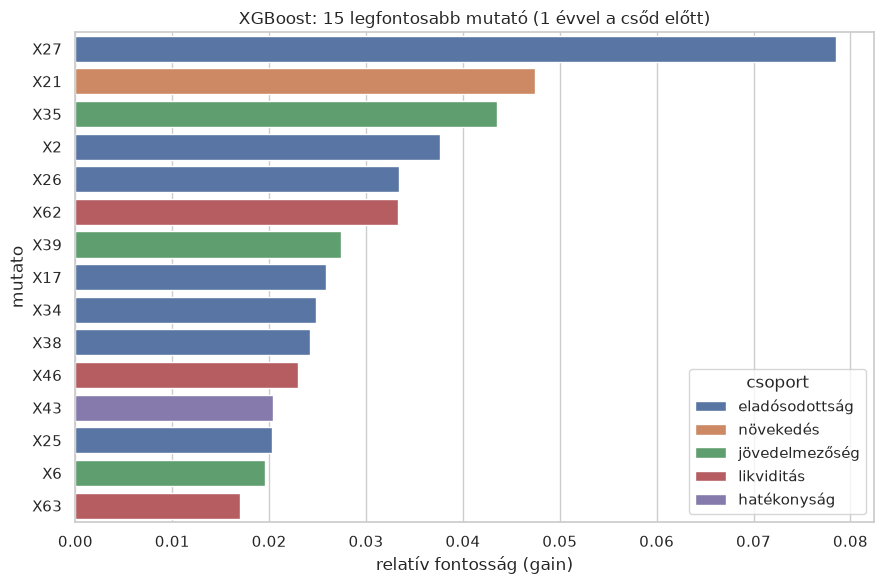

In [9]:
# XGBoost változófontosság (gain) – 1 évvel a csőd előtt, csoportokra is összesítve
fontos = []
for h, g in df.groupby("ev_a_csodig"):
    y = g.csod
    m = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                      scale_pos_weight=(y == 0).sum() / (y == 1).sum(), n_jobs=-1, random_state=42).fit(g[X_COLS], y)
    imp = pd.Series(m.get_booster().get_score(importance_type="gain")).reindex(X_COLS).fillna(0)
    fontos.append(pd.DataFrame({"ev_a_csodig": h, "mutato": X_COLS, "fontossag": imp.values / imp.sum()}))
fontos = pd.concat(fontos)
fontos["csoport"] = fontos.mutato.map(CSOPORT)
t1 = fontos[fontos.ev_a_csodig == 1].nlargest(15, "fontossag").merge(szotar[["mutato", "leiras"]], on="mutato")
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=t1, y="mutato", x="fontossag", hue="csoport", dodge=False, ax=ax)
ax.set_title("XGBoost: 15 legfontosabb mutató (1 évvel a csőd előtt)"); ax.set_xlabel("relatív fontosság (gain)")
fig.tight_layout(); fig.savefig(FIG / "05_xgb_fontossag.png", dpi=200)
display(t1.round(3))
fontos.groupby(["csoport", "ev_a_csodig"]).fontossag.sum().unstack().round(3)

## 4a. Viszonyítás: Altman Z''-score (Altman, 1983/2000 – nem tőzsdei cégekre)
Z' = 0,717·X3 + 0,847·X6 + 3,107·X7 + 0,420·X8 + 0,998·X9; zónák: < 1,23 veszély, > 2,9 biztonságos.

In [10]:
z = 0.717*df.X3 + 0.847*df.X6 + 3.107*df.X7 + 0.420*df.X8 + 0.998*df.X9
df["altman_z"] = z
df["altman_zona"] = pd.cut(z, [-np.inf, 1.23, 2.9, np.inf], labels=["veszély", "szürke", "biztonságos"])
alt = []
for h, g in df.dropna(subset=["altman_z"]).groupby("ev_a_csodig"):
    alt.append(dict(ev_a_csodig=h, auc=roc_auc_score(g.csod, -g.altman_z),
                    recall_veszely=(g[g.csod == 1].altman_zona == "veszély").mean(),
                    tevesen_veszely=(g[g.csod == 0].altman_zona == "veszély").mean()))
pd.DataFrame(alt).round(3)

,ev_a_csodig,auc,recall_veszely,tevesen_veszely
0,1,0.708,0.468,0.123
1,2,0.659,0.388,0.154
2,3,0.657,0.358,0.152
3,4,0.607,0.262,0.151
4,5,0.633,0.266,0.092


## 4b. Bukási profilok: klaszterezés a csődbe ment cégeken (1 évvel a csőd előtt)
K-közép a winsorizált, standardizált kulcsmutatókon.

In [11]:
PROFIL = ["X1", "X2", "X4", "X40", "X10", "X9", "X21"]
b = df[(df.csod == 1) & (df.ev_a_csodig == 1)][PROFIL]
prep = make_pipeline(SimpleImputer(strategy="median"), Winsorizer(0.05), StandardScaler())
Z = prep.fit_transform(b)
from sklearn.metrics import silhouette_score
sil = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=42).fit_predict(Z)) for k in range(2, 7)}
print("Sziluett-érték k szerint:", {k: round(v, 3) for k, v in sil.items()})

Sziluett-érték k szerint: {2: 0.38, 3: 0.433, 4: 0.236, 5: 0.244, 6: 0.221}


In [12]:
K = 3  # sziluett + értelmezhetőség alapján; szükség esetén módosítani
km = KMeans(K, n_init=20, random_state=42).fit(Z)
b = b.assign(klaszter=km.labels_)
mukodo_med = df[(df.csod == 0) & (df.ev_a_csodig == 1)][PROFIL].median()
profil = b.groupby("klaszter")[PROFIL].median()
profil.loc["működő cégek (medián)"] = mukodo_med
profil["db"] = list(b.klaszter.value_counts().sort_index()) + [np.nan]
profil.columns = [f"{c} {KULCS.get(c, szotar.set_index('mutato').leiras.get(c))}" if c != "db" else c for c in profil.columns]
profil.round(3)

,X1 ROA (nettó eredmény / eszközök),X2 Kötelezettségek / eszközök,X4 Likviditási ráta,X40 Pénzeszköz-ráta,X10 Saját tőke / eszközök,X9 sales / total assets,X21 sales (n) / sales (n-1),db
klaszter,,,,,,,,
0,-0.012,0.131,6.181,2.824,0.844,1.114,0.702,41.0
1,-0.047,0.707,0.973,0.046,0.271,1.100,0.927,311.0
2,-0.502,2.339,0.246,0.010,-1.617,1.403,0.856,56.0
működő cégek (medián),0.052,0.436,1.711,0.191,0.538,1.141,1.125,NaN


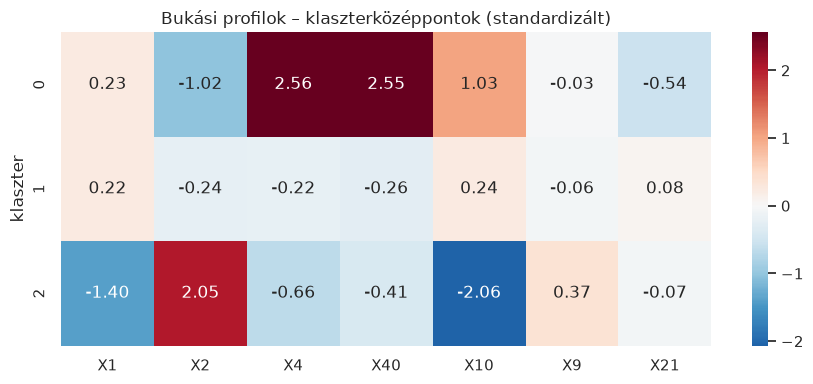

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
cent = pd.DataFrame(km.cluster_centers_, columns=PROFIL)
sns.heatmap(cent, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_ylabel("klaszter"); ax.set_title("Bukási profilok – klaszterközéppontok (standardizált)")
fig.tight_layout(); fig.savefig(FIG / "06_bukasi_profilok.png", dpi=200)